# Credit Card Fraud Detection System
## 01 - Data Understanding

### Project Objective
The objective of this project is to build a machine learning system that identifies potentially fraudulent credit card transactions.

### Dataset Overview
- Dataset: Credit Card Fraud Detection (ULB)
- Total transactions: 284,807
- Total columns: 31
- Target column: `Class`
- `Class = 0`: Legitimate transaction
- `Class = 1`: Fraudulent transaction

In [1]:
import pandas as pd
import numpy as np

# Display all columns in the notebook
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("../data/raw/creditcard.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 284807
Number of columns: 31


In [3]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [5]:
missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

missing_values[missing_values > 0]

Total missing values: 0


Series([], dtype: int64)

In [8]:
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count )

Total duplicate rows: 1081


In [9]:
# Count legitimate and fraudulent transactions
class_counts = df["Class"].value_counts().sort_index()

print(class_counts)

Class
0    284315
1       492
Name: count, dtype: int64


In [10]:
# Calculate class percentages
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

print(class_percentages)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


Matplotlib is building the font cache; this may take a moment.


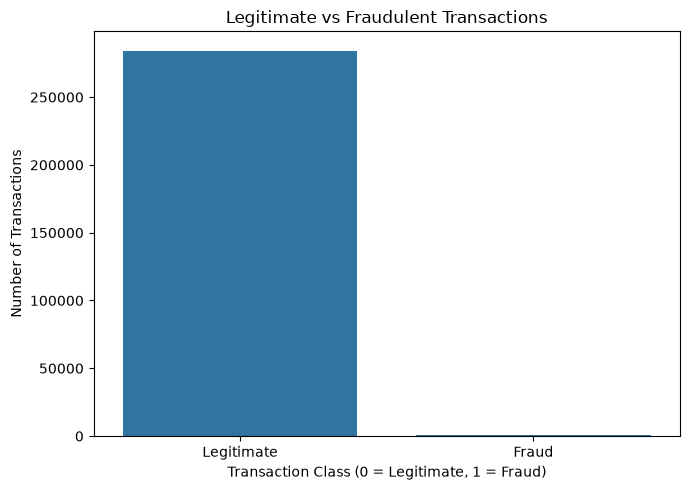

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.tight_layout()
plt.show()

## 2. Transaction Amount Analysis

We will examine the distribution of transaction amounts and compare legitimate transactions with fraudulent transactions.

In [12]:
df["Amount"].describe()

count    284807.000000
mean         88.349619
std         250.120109
min           0.000000
25%           5.600000
50%          22.000000
75%          77.165000
max       25691.160000
Name: Amount, dtype: float64

In [13]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


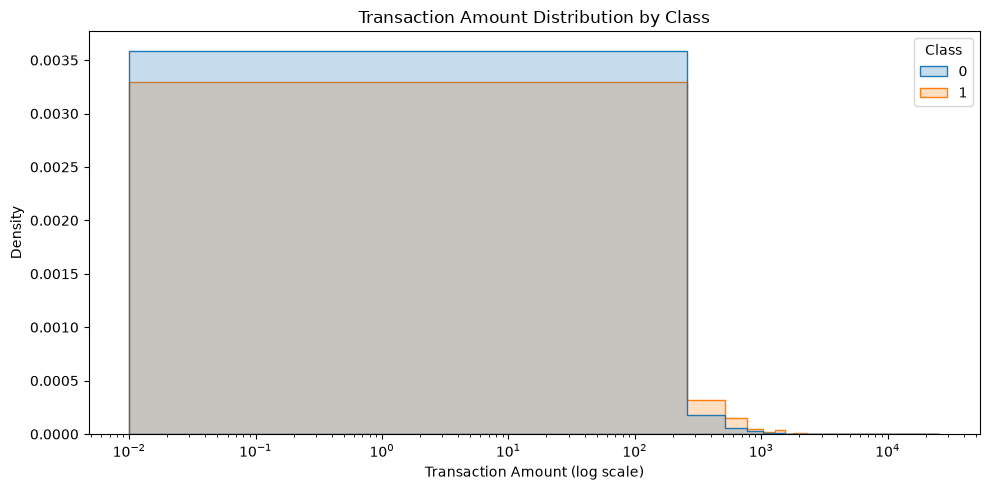

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["Amount"] > 0],
    x="Amount",
    hue="Class",
    bins=100,
    element="step",
    stat="density",
    common_norm=False
)

plt.xscale("log")
plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount (log scale)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

## 3. Transaction Time Analysis

The `Time` column represents elapsed seconds from the beginning of the dataset. We will compare the timing patterns of legitimate and fraudulent transactions.

In [15]:
df.groupby("Class")["Time"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,94838.202258,47484.015786,0.0,54230.0,84711.0,139333.0,172792.0
1,492.0,80746.806911,47835.365138,406.0,41241.5,75568.5,128483.0,170348.0


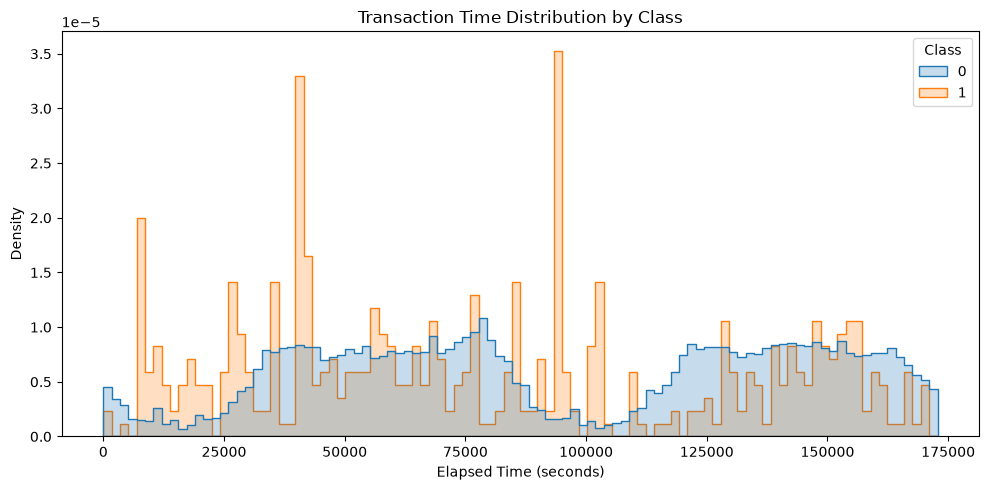

In [16]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=100,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Transaction Time Distribution by Class")
plt.xlabel("Elapsed Time (seconds)")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

## 4. Duplicate Row Analysis

We will investigate duplicate records before deciding whether to remove them.

In [17]:
# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total rows:", len(df))
print("Duplicate rows:", duplicate_count)
print("Duplicate percentage:", round(duplicate_count / len(df) * 100, 3), "%")


Total rows: 284807
Duplicate rows: 1081
Duplicate percentage: 0.38 %


In [18]:
duplicates = df[df.duplicated(keep=False)]

print("Class distribution among rows involved in duplicates:")
print(duplicates["Class"].value_counts())

Class distribution among rows involved in duplicates:
Class
0    1822
1      32
Name: count, dtype: int64


## 5. Feature Correlation Analysis

Correlation helps us understand linear relationships between numerical features and the target variable.

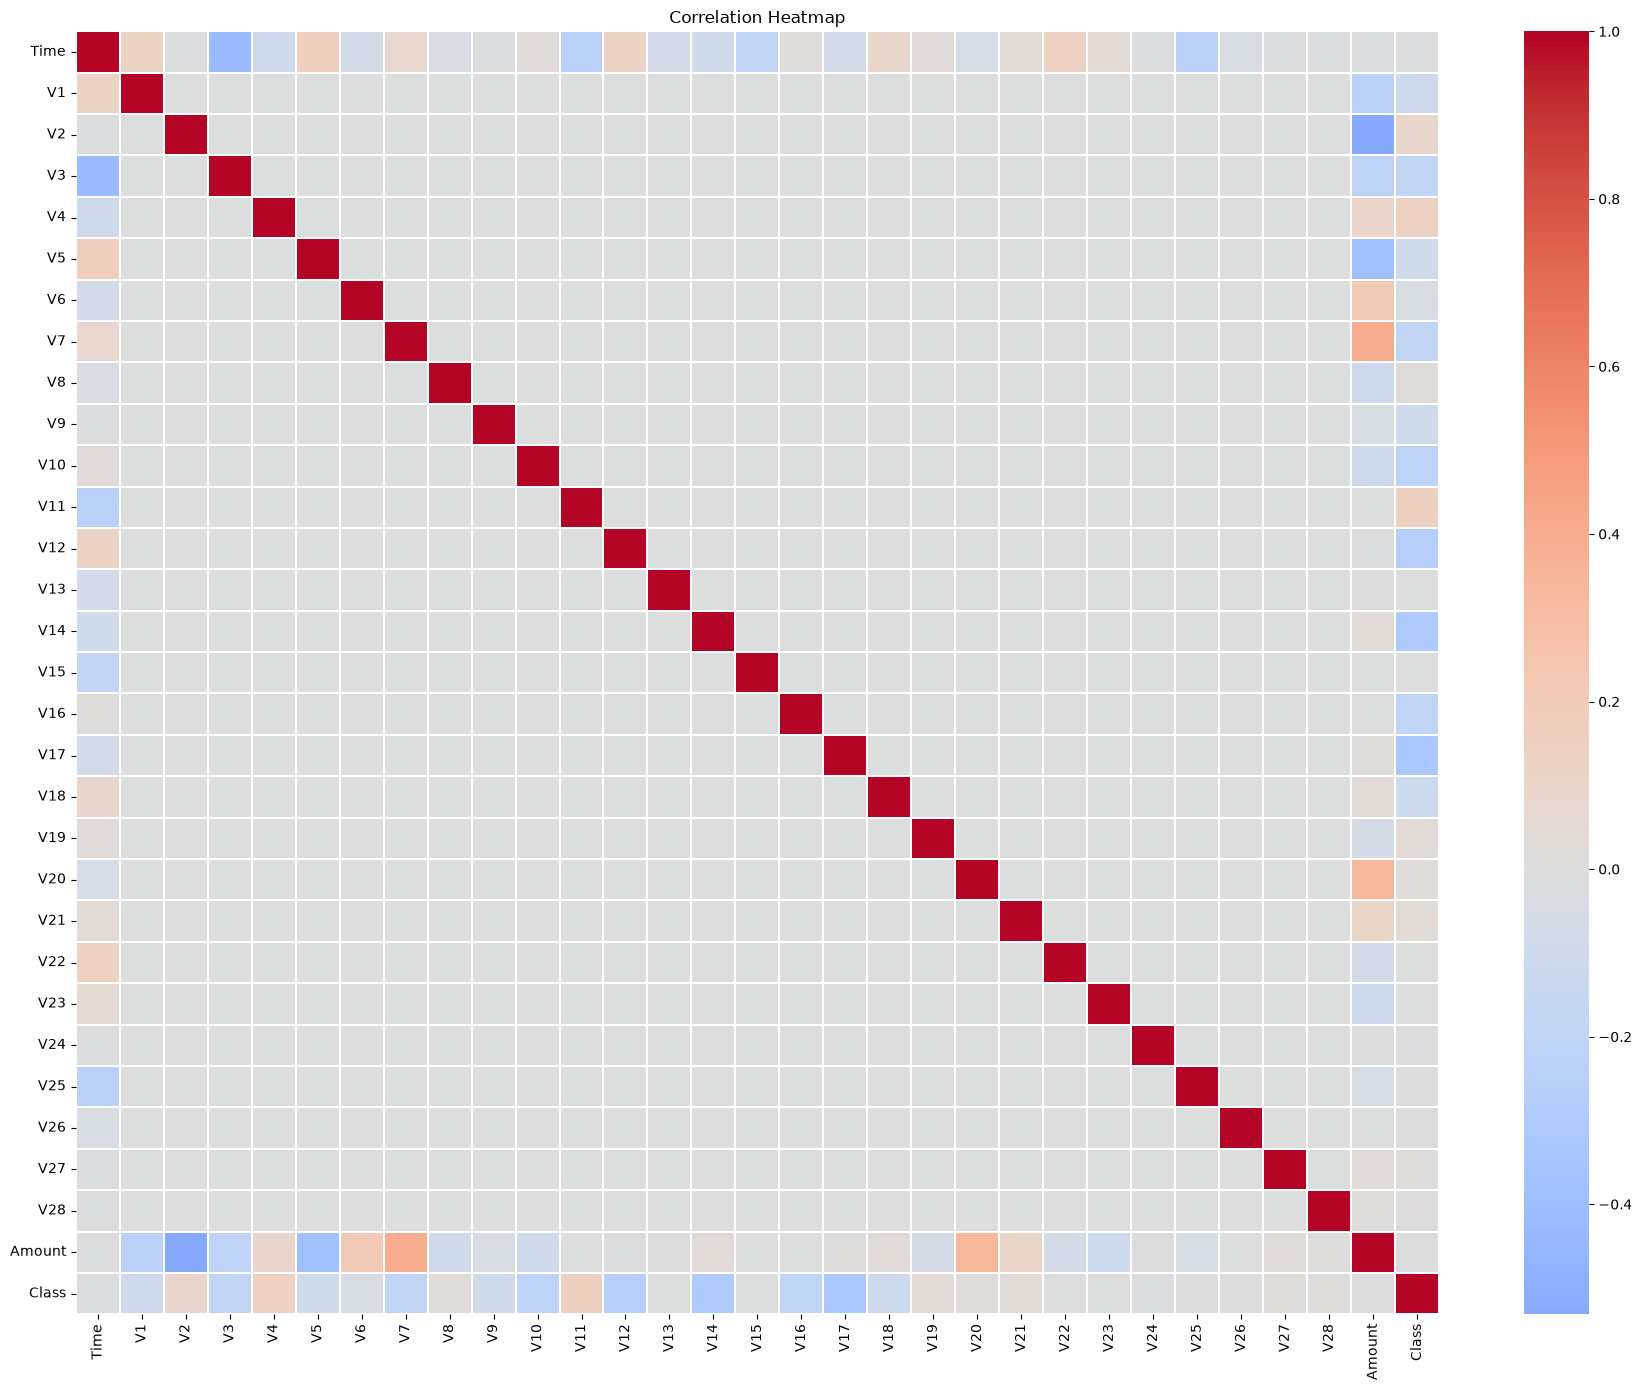

In [19]:
correlation = df.corr(numeric_only=True)

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [20]:
class_correlation = (
    correlation["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
)

class_correlation

V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V11       0.154876
V4        0.133447
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V2        0.091289
V6       -0.043643
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
Time     -0.012323
V28       0.009536
V24      -0.007221
Amount    0.005632
V13      -0.004570
V26       0.004455
V15      -0.004223
V25       0.003308
V23      -0.002685
V22       0.000805
Name: Class, dtype: float64

## 6. Initial EDA Findings

1. The dataset contains 284,807 transactions and 31 columns.
2. The target variable is `Class`, where 0 represents legitimate transactions and 1 represents fraudulent transactions.
3. The dataset contains 492 fraudulent transactions, approximately 0.173% of all transactions.
4. No missing values were found during the initial data-quality check.
5. A total of 1,081 duplicate rows were identified. Their treatment requires further investigation.
6. Transaction amount, elapsed time, and feature correlations were explored to identify potential patterns.
7. Because the target classes are highly imbalanced, model evaluation must include precision, recall, F1-score, and PR-AUC rather than relying on accuracy alone.